# pre-calculate the relations between concepts

In [1]:
import os

from pathlib import Path
os.chdir(Path.cwd().parent)

from pathlib import Path
import json
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm.autonotebook import tqdm

from modules.kg import adjacency_list
from utils.llm import load_model
from modules.blacklists import *
from sklearn.metrics.pairwise import cosine_similarity
from utils.multiprocess import multiprocess_call

llm = load_model({"model": "DeepSeek-V3-671B", "server": "ant"})

/var/folders/7n/7q2l54n506s6zkdh0dcz9_sm0000gn/T/ipykernel_55581/71274937.py:10: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


edge_index.shape torch.Size([2, 230872])
Self-loop detected, Removed


In [2]:
condition_dict, procedure_dict, drug_dict = load_mappings()
all_cond = list(condition_dict.values())
all_proc = list(procedure_dict.values())
all_drug = list(drug_dict.values())
print(len(all_cond), len(all_proc), len(all_drug))

285 231 269


In [6]:
from collections import defaultdict
input_pairs = defaultdict(list)
for corpus in [all_cond]:
    filtered_by_node_rule, filtered_by_rel_rule = [], []
    print(len(corpus))
    for a in corpus:
        for b in corpus:
            if a == b or a not in graph.entities or b not in graph.entities: continue
            for rel, neighbor in adjacency_list[graph.entity2id[a]]:
                if neighbor != graph.entity2id[b]: continue
                rel = graph.graph.relation[rel].item()
                rel = graph.id2relation[rel]

                # if any(w in a.lower() or w in b.lower() for w in blacklist_entity):
                #     filtered_by_node_rule.append((a, rel, b))
                #     continue
                # if any(w in rel.lower() for w in negative_relation + vague_relation):
                #     filtered_by_rel_rule.append((a, rel, b))
                #     continue
                if hash(a) < hash(b):
                    input_pairs[(a, b)].append((a,rel,b))
                else:
                    input_pairs[(b, a)].append((a,rel,b))

    # print(len(filtered_by_node_rule))
    # if filtered_by_node_rule:
    #     print(random.choice(filtered_by_node_rule))
    # print(len(filtered_by_rel_rule), random.choice(filtered_by_rel_rule))
    print(len(input_pairs), end="\n\n")

285
10038



## embedding-based

In [ ]:
emb_output = []
for a, rel, b in tqdm(input_pairs):
    emb_output.append((a, b,
                       cosine_similarity(graph.entity2embedding[a].numpy().reshape(1, -1),
                                         graph.entity2embedding[b].numpy().reshape(1, -1)).item()))

print(np.mean([item[2] for item in emb_output]))
print(np.median([item[2] for item in emb_output]))
print(np.max([item[2] for item in emb_output]))
print(np.min([item[2] for item in emb_output]))

plt.hist([item[2] for item in emb_output], bins=100)
plt.show()

In [ ]:
emb_output_dict = {}
for src, dst, pred in emb_output:
    emb_output_dict[f"{src}-{dst}"] = pred

json.dump(emb_output_dict, Path("./Reasoner/cache/emb_pairwise.json").open('w', encoding='utf-8'))

## llm-based

In [3]:
prompt = """\
# Instruction
Determine whether the concepts are related to the same disease or body part and should be treated as a single disease.
Please provide a brief reasoning. Then, provide your prediction with "YES" or "NO".

# Example
Concept: Hypertension
Candidate: Coronary artery disease
Relation: Coronary artery disease -> can occur with -> Hypertension
Answer: Hypertension and coronary artery disease are both cardiovascular conditions, affecting the same body system (heart and blood vessels). YES.

Concept: Gastritis
Candidate: Peptic Ulcer
Relation: Peptic Ulcer -> increase risk of -> Gastritis
Answer: Gastritis and peptic ulcer both involve the stomach (upper GI tract). YES.

Concept: Osteoarthritis
Candidate: Allergic Rhinitis
Relation: Allergic Rhinitis -> can coexist with -> Osteoarthritis
Answer: Osteoarthritis is a joint disorder, while the candidate is respiratory/allergic and unrelated anatomically or pathologically. NO.

Concept: Respiratory failure; insufficiency; arrest
Candidate: Gastrointestinal disorders
Relation: respiratory failure; insufficiency; arrest -> suggests -> gastrointestinal disorders
Answer: They affect distinct organ systems, have different underlying causes, symptoms, diagnostic criteria, and treatment approaches. NO.

# Input
Concept: ##CONCEPT_PLACEHOLDER##
Candidate: ##CANDIDATE_PLACEHOLDER##
Relation: ##RELATION_PLACEHOLDER##

# Output
Answer: [Reasoning then YES or NO]
"""

In [4]:
def post_process(prob, response, output):
    answer = response.split("Answer")[-1]
    if "YES" in answer and "NO" not in answer:
        prediction = True
    elif "NO" in answer and "YES" not in answer:
        prediction = False
    else:
        raise ValueError

    return prob, prediction, output


def reason_relation_pairwise(src, dst, rels):
    relations = "\n".join(f"{rel[0]}->{rel[1]}->{rel[2]}" for rel in rels)
    query = prompt.replace("##CONCEPT_PLACEHOLDER##", src) \
        .replace("##CANDIDATE_PLACEHOLDER##", dst) \
        .replace("##RELATION_PLACEHOLDER##", relations)
    _, prediction, _ = llm.understand(query, post_process=post_process, verbose=False)
    return src, dst, int(prediction)


def reason_relation_pairwise_thread(key, item):
    k, v = item
    return key, reason_relation_pairwise(k[0], k[1], v)

In [5]:
llm_output = []

In [8]:
input_pairs_list = [(k, v) for k, v in input_pairs.items()]
llm_output = multiprocess_call(reason_relation_pairwise_thread,
                               input_pairs_list, llm_output, n_workers=16)

  0%|          | 0/1044 [00:00<?, ?it/s]

0.20533227218463987
0.0
1
0


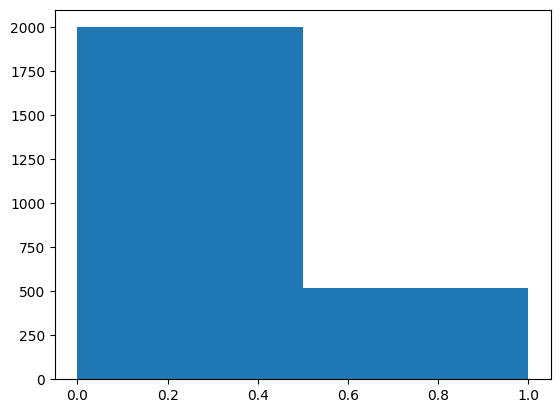

In [9]:
print(np.mean([item[2] for item in llm_output]))
print(np.median([item[2] for item in llm_output]))
print(np.max([item[2] for item in llm_output]))
print(np.min([item[2] for item in llm_output]))

plt.hist([item[2] for item in llm_output], bins=2)
plt.show()

In [10]:
llm_output_dict = {}
for src, dst, pred in llm_output:
    llm_output_dict[f"{src}-{dst}"] = pred

In [11]:
from pathlib import Path
import json

json.dump(llm_output_dict, Path("./Reasoner/cache/llm_drug_pairwise.json").open('w', encoding='utf-8'))